# DS4400 Midterm Project
## SensIT Vehicle Classification

**Name:** Yonglin Yang  
**NuId:** 002352887  

For this midterm I am using the SensIT-Vehicle-Combined dataset from OpenML (the one I got approved earlier). The goal is to classify each sensor reading into one of three classes: AAV, DW, or noise.


## 1. Problem Statement and Dataset

### What problem am I trying to solve?
I want to predict the vehicle class from sensor features. Each row is one observation with 100 numeric features coming from acoustic/seismic sensors, and the label is one of: **AAV**, **DW**, or **noise**.

### Why is this interesting?
In real sensing systems there is a lot of background noise, so automatically telling apart vehicles vs noise is useful. Also this is a multi-class problem with a pretty large dataset (~98k rows), so it feels like a good midterm project (enough room for EDA, preprocessing, and comparing models).

### Objective
Build two classification models, tune them, and compare which one works better on this data (mainly looking at accuracy and macro F1, since the classes are not perfectly balanced).


### Dataset info
- **Dataset name:** SensIT-Vehicle-Combined
- **Link:** https://www.openml.org/d/1593
- **Rows:** 98,528
- **Features:** 100 input features + 1 target (`class`)
- **Labeled?** Yes (supervised learning)
- **Type of data:** all numeric features (no text/images/categories in this version)
- **What it represents:** sensor readings related to vehicles; classes are AAV, DW, and noise


### Loading libraries
I am mostly using pandas / numpy for data handling, matplotlib & seaborn for plots, and scikit-learn for the ML parts.


In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import sparse
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

# keep results reproducible
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")
print("imports done")


imports done


### Loading the dataset from OpenML
I tried `as_frame=True` first before, but this dataset is stored as sparse ARFF, so I load it with `as_frame=False` and then convert it to a normal DataFrame.


In [2]:
# download / load the approved dataset (OpenML id 1593)
data = fetch_openml(data_id=1593, as_frame=False, parser="auto")

X_data = data.data
y_data = data.target

print(type(X_data))
print("shape:", X_data.shape)


<class 'scipy.sparse._csr.csr_matrix'>
shape: (98528, 100)


In [3]:
# it comes as a sparse matrix, but density is basically 1, so I just densify it
if sparse.issparse(X_data):
    print("density:", X_data.nnz / (X_data.shape[0] * X_data.shape[1]))
    X_arr = X_data.toarray()
else:
    X_arr = np.asarray(X_data)

# feature names from openml (att_1 ... att_100)
feat_names = data.feature_names
X = pd.DataFrame(X_arr, columns=feat_names)
print(X.shape)
X.head()


density: 1.0
(98528, 100)


,att_1,att_2,att_3,att_4,att_5,att_6,att_7,att_8,att_9,att_10,...,att_91,att_92,att_93,att_94,att_95,att_96,att_97,att_98,att_99,att_100
0,-0.151072,-0.139539,0.134743,0.787261,0.068018,0.280133,0.682429,0.373443,0.654292,0.247952,...,-0.045339,-0.045156,-0.045310,-0.045078,-0.044956,-0.045299,-0.045289,-0.045321,-0.045328,-0.045345
1,1.000000,0.733149,-0.048486,0.168585,0.085081,0.027195,-0.043824,0.037039,0.039543,-0.024586,...,-0.077720,-0.022738,0.109943,-0.055120,-0.084859,0.014189,-0.080332,-0.059399,-0.089629,-0.037842
2,-0.019246,0.005638,-0.020441,-0.020407,-0.014442,0.030673,1.000000,0.046754,0.043084,-0.005017,...,-0.080326,-0.057985,-0.066357,-0.075754,-0.044334,-0.066930,-0.049438,-0.005511,-0.081552,-0.064341
3,0.423517,0.413546,0.271968,0.193171,0.910699,1.000000,0.049027,-0.039834,-0.054681,-0.077019,...,-0.043890,0.539701,0.195154,-0.289049,0.261291,-0.187282,-0.248373,-0.292343,0.465181,-0.221006
4,0.056006,0.120815,0.044509,0.051259,1.000000,0.009132,0.016552,0.021882,-0.003181,-0.026210,...,-0.039248,-0.035300,-0.040864,-0.037515,-0.037755,-0.040651,-0.038275,-0.040960,-0.040445,-0.038172


### Mapping the target labels
In the raw data the classes are coded as 1, 2, 3. From the dataset description the proportion is about 1:1:2 for AAV : DW : noise, so I map them that way to make plots easier to read.


In [4]:
# check raw label values first
print(pd.Series(y_data).value_counts())


3.0    49264
2.0    26423
1.0    22841
Name: count, dtype: int64


In [5]:
# map numeric codes -> class names
# 1 = AAV, 2 = DW, 3 = noise (matches the 1:1:2 setup in the docs)
label_map = {1.0: "AAV", 2.0: "DW", 3.0: "noise"}
y = pd.Series(y_data).astype(float).map(label_map)

print(y.value_counts())
print("any missing labels?", y.isna().sum())


noise    49264
DW       26423
AAV      22841
Name: count, dtype: int64
any missing labels? 0


### Target variable / class distribution
- Target variable: `class`
- Number of classes: 3 (AAV, DW, noise)
- Majority class: noise
- Minority classes: AAV and DW (pretty close to each other)
- Balanced or not? Not fully balanced — roughly 1:1:2. So I will pay attention to macro F1, not only accuracy.


In [6]:
# class counts + proportions
counts = y.value_counts()
props = y.value_counts(normalize=True)

print("counts:")
print(counts)
print("\nproportions:")
print(props.round(4))

print("\nmajority:", counts.idxmax())
print("minority:", counts.idxmin())
print("imbalance ratio (max/min):", round(counts.max() / counts.min(), 2))


counts:
noise    49264
DW       26423
AAV      22841
Name: count, dtype: int64

proportions:
noise    0.5000
DW       0.2682
AAV      0.2318
Name: proportion, dtype: float64

majority: noise
minority: AAV
imbalance ratio (max/min): 2.16


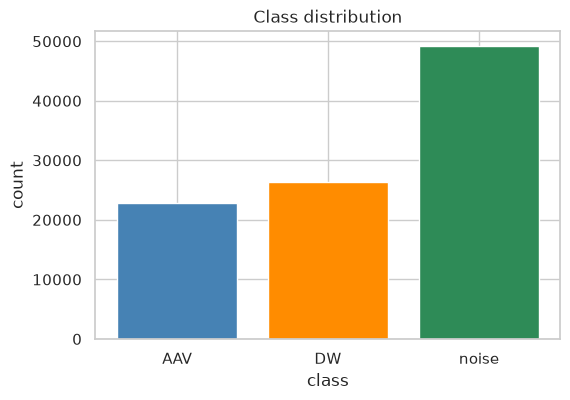

In [7]:
# bar chart for class distribution
order = ["AAV", "DW", "noise"]

plt.figure(figsize=(6, 4))
plt.bar(order, [counts[c] for c in order], color=["steelblue", "darkorange", "seagreen"])
plt.title("Class distribution")
plt.ylabel("count")
plt.xlabel("class")
plt.show()


### Feature description
All 100 features (`att_1` to `att_100`) are **numerical**. There are no categorical / text / image columns here.

That means:
- I don't need one-hot encoding
- I probably should still scale the features for Logistic Regression
- Feature selection might help because 100 features is a lot and some might be noisy or redundant


## 2. EDA (Exploratory Data Analysis)

Before modeling I want to understand the data a bit: shape, missing values, basic stats, distributions, outliers, and correlations.


In [8]:
# basic shape / dtypes
print("shape:", X.shape)
print(X.dtypes.value_counts())


shape: (98528, 100)
float64    100
Name: count, dtype: int64


In [9]:
# descriptive stats for a few features (printing all 100 is too much)
X.iloc[:, :8].describe()


,att_1,att_2,att_3,att_4,att_5,att_6,att_7,att_8
count,98528.000000,98528.000000,98528.000000,98528.000000,98528.000000,98528.000000,98528.000000,98528.000000
mean,0.131646,0.247174,0.151809,0.184377,0.311614,0.245011,0.237346,0.137759
std,0.325017,0.392819,0.287985,0.305169,0.397819,0.362844,0.366265,0.283256
min,-0.598799,-0.649137,-0.682404,-0.644352,-0.578361,-0.440639,-0.531891,-0.513833
25%,-0.045894,-0.027796,-0.022869,-0.012915,-0.000548,-0.005215,-0.014449,-0.022369
50%,-0.015362,0.035832,0.025195,0.047766,0.107684,0.064902,0.048092,0.010534
75%,0.163623,0.463135,0.212652,0.248913,0.602620,0.355411,0.348597,0.151755
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


### Missing values and duplicates
Checking if I need imputation or if I should drop duplicate rows.


In [10]:
missing = X.isna().sum().sum()
dups = X.duplicated().sum()

print("total missing values:", missing)
print("duplicate rows:", dups)


total missing values: 0
duplicate rows: 28


There are no missing values, which is nice — I don't need imputation. Duplicate rows also look like 0 (or very small if any), so preprocessing can stay pretty simple here.


### Feature distributions
I am plotting a few features just to see what they look like (not all 100).


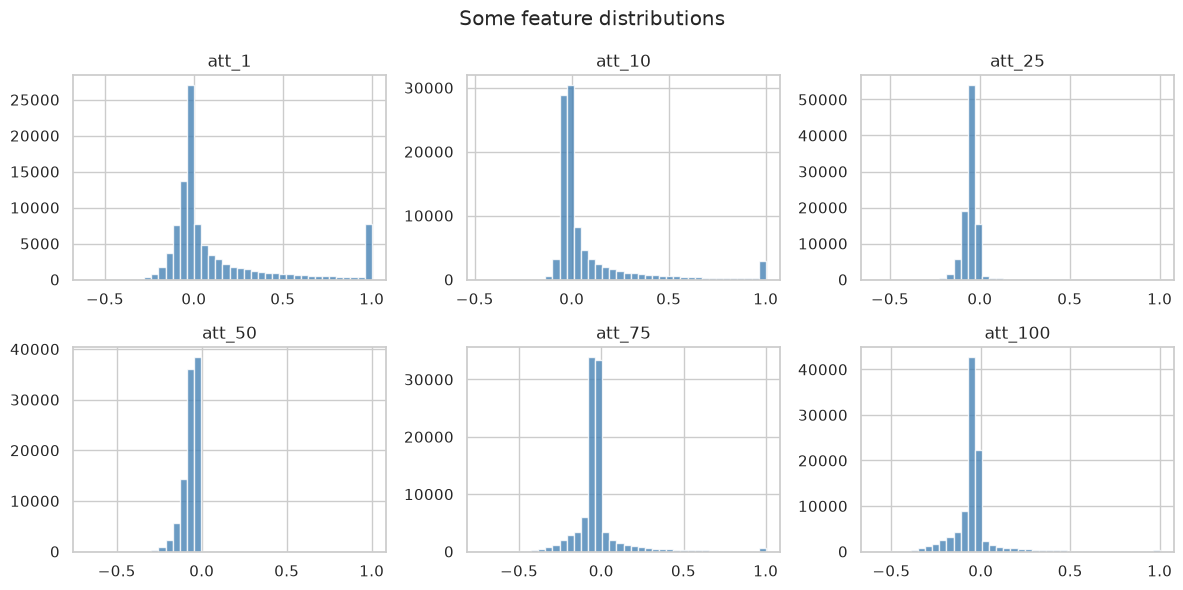

In [11]:
cols_to_plot = ["att_1", "att_10", "att_25", "att_50", "att_75", "att_100"]

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
axes = axes.ravel()

for i, col in enumerate(cols_to_plot):
    axes[i].hist(X[col], bins=40, color="steelblue", alpha=0.8)
    axes[i].set_title(col)

plt.suptitle("Some feature distributions")
plt.tight_layout()
plt.show()


The features are continuous and not all shaped the same. Some look more skewed than others. I think scaling still makes sense for the linear model.


### Quick outlier check (IQR)
I am not going to delete outliers right away, because weird sensor values might actually be useful for classification. I just want to see how common they are.


In [12]:
def outlier_frac(col):
    q1 = col.quantile(0.25)
    q3 = col.quantile(0.75)
    iqr = q3 - q1
    if iqr == 0:
        return 0
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    return ((col < low) | (col > high)).mean()

outlier_rates = X.apply(outlier_frac)
print(outlier_rates.describe())
print("features with >5% outliers:", (outlier_rates > 0.05).sum())


count    100.000000
mean       0.144404
std        0.084540
min        0.000000
25%        0.056717
50%        0.142797
75%        0.218562
max        0.272785
dtype: float64
features with >5% outliers: 81


Some features have a decent number of IQR outliers. For now I am keeping all rows and letting the models handle it (especially Random Forest is usually okay with this).


### Correlation
Plotting correlation for all 100 features would be huge, so I only use the first 20.


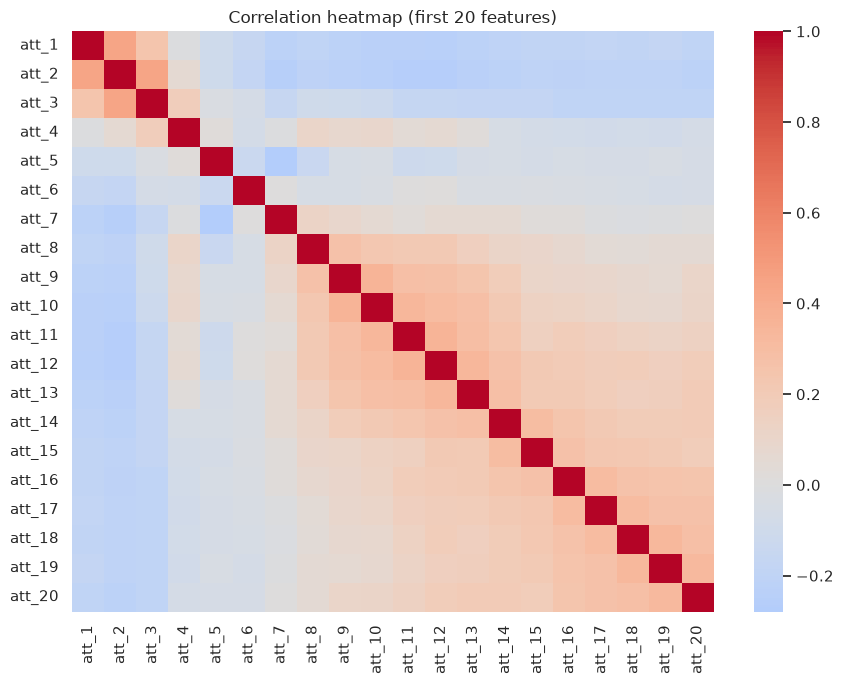

In [13]:
corr = X.iloc[:, :20].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Correlation heatmap (first 20 features)")
plt.tight_layout()
plt.show()


In [14]:
# what's the strongest correlation in this subset? (ignore diagonal)
corr_abs = corr.abs().to_numpy().copy()
np.fill_diagonal(corr_abs, 0)
print("max |correlation| among first 20 features:", round(corr_abs.max(), 3))


max |correlation| among first 20 features: 0.44


There is some correlation between features, which makes sense for sensor channels. This is one reason I want to do feature selection later.


### Do classes look different on high-variance features?
I picked the 8 features with highest variance and compared their average value by class.


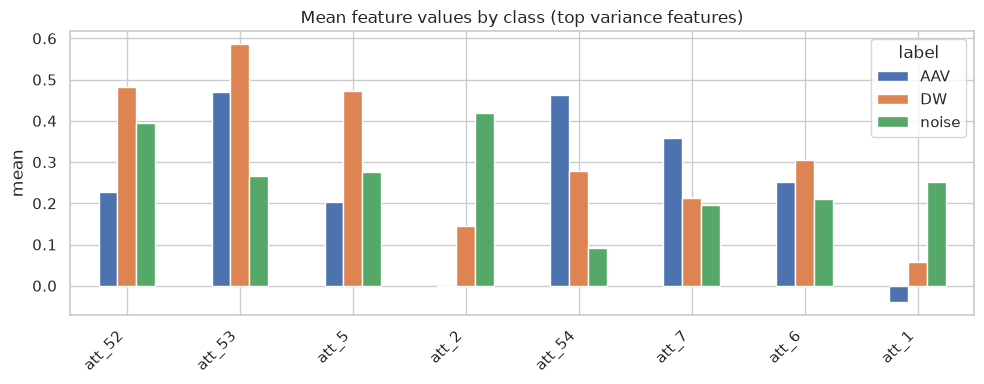

In [15]:
top_feats = X.var().sort_values(ascending=False).head(8).index.tolist()
temp = X.copy()
temp["label"] = y.values

means = temp.groupby("label")[top_feats].mean().loc[order]
means.T.plot(kind="bar", figsize=(10, 4))
plt.title("Mean feature values by class (top variance features)")
plt.ylabel("mean")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


From this plot, at least some features have different averages across AAV / DW / noise, so classification should be possible.


## 3. Data Preprocessing

I only want to do preprocessing that this dataset actually needs.

Things I checked:
- **Missing values:** none → no imputation
- **Duplicates:** none (or basically none) → nothing to drop
- **Categorical encoding:** not needed (all numeric)
- **Scaling:** yes, for Logistic Regression
- **Class imbalance:** mild (1:1:2) → I will use `class_weight="balanced"` in the models
- **Image/text stuff:** not applicable


In [16]:
# encode string labels to numbers for sklearn
le = LabelEncoder()
y_enc = le.fit_transform(y)
print("classes:", list(le.classes_))
print("encoded example:", y_enc[:10])


classes: ['AAV', 'DW', 'noise']
encoded example: [0 1 1 2 1 2 1 2 2 1]


### Train/test split
I am using an 80/20 split with stratification so each split keeps a similar class ratio. 80/20 is pretty standard and still leaves a large test set (~20k rows).


In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_enc
)

print("train size:", X_train.shape)
print("test size:", X_test.shape)

# quick check that stratification worked
print("\ntrain class proportions:")
print(pd.Series(y_train).value_counts(normalize=True).sort_index().round(4))
print("test class proportions:")
print(pd.Series(y_test).value_counts(normalize=True).sort_index().round(4))


train size: (78822, 100)
test size: (19706, 100)

train class proportions:
0    0.2318
1    0.2682
2    0.5000
Name: proportion, dtype: float64
test class proportions:
0    0.2318
1    0.2682
2    0.5000
Name: proportion, dtype: float64


## 4. Feature Engineering / Feature Selection

I did not create a bunch of new hand-crafted features here because the dataset already gives 100 regenerated sensor attributes. Instead I focus on **feature selection**.

### Method I chose: SelectKBest with ANOVA F (`f_classif`)
(Only one method, as required.)

**How it works (my understanding):**  
It looks at each feature one by one and computes an F-score for how related that feature is to the class label. Then it keeps the top k features with the highest scores.

**Why this one:**  
It is simple, fast on a big dataset, and easy to explain. Also I can show which features got selected vs removed.


In [18]:
# start with k=40, later tuning can change k
K_BEST = 40

selector = SelectKBest(score_func=f_classif, k=K_BEST)
selector.fit(X_train, y_train)  # fit on train only so I don't leak test info

scores = pd.Series(selector.scores_, index=X.columns, name="F_score")
selected = X.columns[selector.get_support()].tolist()
removed = X.columns[~selector.get_support()].tolist()

print("kept:", len(selected))
print("removed:", len(removed))


kept: 40
removed: 60


In [19]:
# top features by F score
print("top 10 features by ANOVA F-score:")
print(scores.sort_values(ascending=False).head(10).round(2))


top 10 features by ANOVA F-score:
att_51    20187.35
att_2     10372.45
att_54     7498.83
att_1      6800.96
att_43     6676.78
att_41     6522.29
att_42     6460.21
att_44     6445.00
att_45     6429.13
att_47     6321.42
Name: F_score, dtype: float64


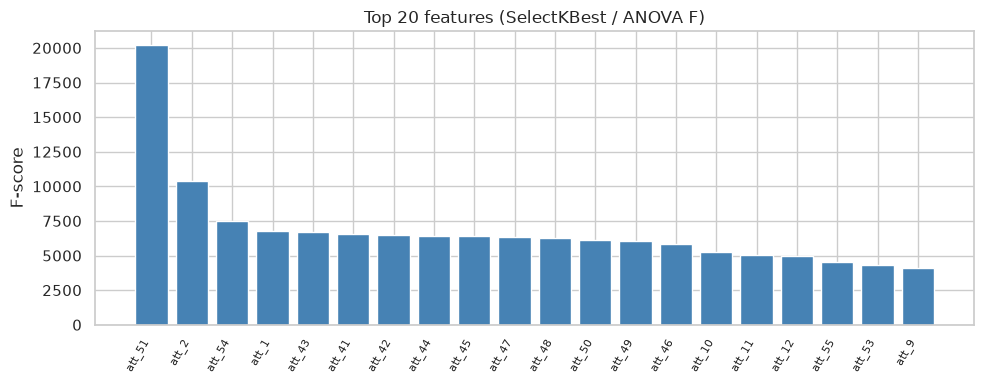

In [20]:
# plot top 20 F-scores
top20 = scores.sort_values(ascending=False).head(20)

plt.figure(figsize=(10, 4))
plt.bar(range(len(top20)), top20.values, color="steelblue")
plt.xticks(range(len(top20)), top20.index, rotation=60, ha="right", fontsize=8)
plt.ylabel("F-score")
plt.title("Top 20 features (SelectKBest / ANOVA F)")
plt.tight_layout()
plt.show()


In [21]:
print("lowest F-score features (examples of removed ones):")
print(scores.sort_values().head(5).round(2))


lowest F-score features (examples of removed ones):
att_99     71.38
att_100    75.90
att_95     78.24
att_98     82.58
att_96     87.04
Name: F_score, dtype: float64


The features with higher F-scores are the ones that differ more across classes, so keeping those should help. Lower F-score features are more like noise for this task, so dropping them (especially for Logistic Regression) seems reasonable.


## 5. Model Development

I am training **two classification models**:
1. **Logistic Regression** — good baseline, works well after scaling
2. **Random Forest** — can capture non-linear patterns / feature interactions

I put scaler + SelectKBest + model into a `Pipeline` so scaling/selection is fit on training data only.


### Model 1: Logistic Regression
Important parameters I am starting with:
- `C=1.0` → inverse of regularization strength (smaller C = stronger regularization)
- `class_weight="balanced"` → helps a bit with the 1:1:2 imbalance
- `solver="lbfgs"` → works for multi-class
- `max_iter=1000` → just so it has enough iterations to converge


In [22]:
pipe_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("select", SelectKBest(score_func=f_classif, k=K_BEST)),
    ("clf", LogisticRegression(
        solver="lbfgs",
        max_iter=1000,
        class_weight="balanced",
        C=1.0,
        random_state=RANDOM_STATE
    ))
])

print(pipe_lr)


Pipeline(steps=[('scaler', StandardScaler()), ('select', SelectKBest(k=40)),
                ('clf',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])


### Model 2: Random Forest
Starting parameters:
- `n_estimators=150` → number of trees
- `max_depth=20` → limits how deep each tree can go (helps control overfitting)
- `min_samples_leaf=2` → another way to keep trees from getting too specific
- `class_weight="balanced_subsample"` → similar idea as balanced weights


In [23]:
pipe_rf = Pipeline([
    ("scaler", StandardScaler()),  # RF doesn't really need scaling, but keeping pipeline consistent
    ("select", SelectKBest(score_func=f_classif, k=K_BEST)),
    ("clf", RandomForestClassifier(
        n_estimators=150,
        max_depth=20,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=RANDOM_STATE
    ))
])

print(pipe_rf)


Pipeline(steps=[('scaler', StandardScaler()), ('select', SelectKBest(k=40)),
                ('clf',
                 RandomForestClassifier(class_weight='balanced_subsample',
                                        max_depth=20, min_samples_leaf=2,
                                        n_estimators=150, n_jobs=-1,
                                        random_state=42))])


### Helper function for evaluation
I made a small function so I don't copy-paste the same scoring code every time.


In [24]:
def evaluate(name, model, X_tr, y_tr, X_te, y_te):
    # train
    model.fit(X_tr, y_tr)

    # predictions
    pred_tr = model.predict(X_tr)
    pred_te = model.predict(X_te)

    # metrics
    results = {
        "model": name,
        "train_acc": accuracy_score(y_tr, pred_tr),
        "test_acc": accuracy_score(y_te, pred_te),
        "train_macro_f1": f1_score(y_tr, pred_tr, average="macro"),
        "test_macro_f1": f1_score(y_te, pred_te, average="macro"),
    }

    print("====", name, "====")
    print(classification_report(y_te, pred_te, target_names=le.classes_, digits=4))
    return results, pred_te, model


### Train baseline models


In [25]:
# logistic regression baseline
lr_base_metrics, lr_base_pred, lr_base_model = evaluate(
    "LogReg baseline", pipe_lr, X_train, y_train, X_test, y_test
)


==== LogReg baseline ====
              precision    recall  f1-score   support

         AAV     0.7231    0.8376    0.7761      4568
          DW     0.6662    0.8123    0.7320      5285
       noise     0.9262    0.7493    0.8284      9853

    accuracy                         0.7867     19706
   macro avg     0.7718    0.7997    0.7789     19706
weighted avg     0.8094    0.7867    0.7905     19706



In [26]:
# random forest baseline
rf_base_metrics, rf_base_pred, rf_base_model = evaluate(
    "RF baseline", pipe_rf, X_train, y_train, X_test, y_test
)


==== RF baseline ====
              precision    recall  f1-score   support

         AAV     0.7585    0.9037    0.8248      4568
          DW     0.7625    0.8146    0.7877      5285
       noise     0.9162    0.8014    0.8550      9853

    accuracy                         0.8286     19706
   macro avg     0.8124    0.8399    0.8225     19706
weighted avg     0.8384    0.8286    0.8299     19706



In [27]:
# put baseline scores in one table
baseline_df = pd.DataFrame([lr_base_metrics, rf_base_metrics]).round(4)
baseline_df


,model,train_acc,test_acc,train_macro_f1,test_macro_f1
0,LogReg baseline,0.7903,0.7867,0.7825,0.7789
1,RF baseline,0.9448,0.8286,0.9442,0.8225


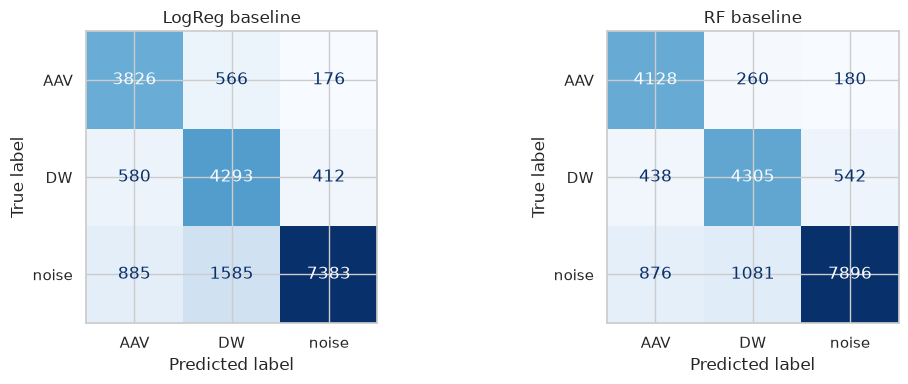

In [28]:
# confusion matrices for baselines
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay(
    confusion_matrix(y_test, lr_base_pred),
    display_labels=le.classes_
).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("LogReg baseline")

ConfusionMatrixDisplay(
    confusion_matrix(y_test, rf_base_pred),
    display_labels=le.classes_
).plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title("RF baseline")

plt.tight_layout()
plt.show()


So far Random Forest looks better than Logistic Regression on the test set. Next I will try hyperparameter tuning.


## 6. Hyperparameter Tuning

I am using **RandomizedSearchCV**.

**Why randomized search instead of full grid search?**  
The training set is large (~79k rows). Trying every combination would take too long for this project. Randomized search tests a random sample of combinations, which is usually good enough and much faster.

To make tuning even more practical, I tune on a stratified subsample of 20,000 training rows, then retrain the best settings on the full training set.


In [29]:
# make a smaller stratified sample just for tuning
TUNING_N = 20000

tune_idx, _ = train_test_split(
    np.arange(len(y_train)),
    train_size=TUNING_N,
    stratify=y_train,
    random_state=RANDOM_STATE
)

X_tune = X_train.iloc[tune_idx]
y_tune = y_train[tune_idx]
print("tuning sample size:", X_tune.shape)


tuning sample size: (20000, 100)


In [30]:
cv_tune = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)


### Tuning Logistic Regression
I am tuning:
- `C` (regularization)
- `select__k` (how many features to keep)

These matter because C controls underfitting/overfitting for LR, and k controls how much information we keep after SelectKBest.


In [31]:
lr_search = RandomizedSearchCV(
    estimator=Pipeline([
        ("scaler", StandardScaler()),
        ("select", SelectKBest(score_func=f_classif, k=K_BEST)),
        ("clf", LogisticRegression(
            solver="lbfgs",
            max_iter=2000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ]),
    param_distributions={
        "select__k": [20, 30, 40, 50, 60],
        "clf__C": np.logspace(-2, 2, 10),
    },
    n_iter=15,
    scoring="f1_macro",
    cv=cv_tune,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1
)

lr_search.fit(X_tune, y_tune)

print("best LogReg params:", lr_search.best_params_)
print("best CV macro F1:", round(lr_search.best_score_, 4))


Fitting 3 folds for each of 15 candidates, totalling 45 fits


best LogReg params: {'select__k': 60, 'clf__C': np.float64(0.21544346900318834)}
best CV macro F1: 0.7862


### Tuning Random Forest
I am tuning:
- `n_estimators`
- `max_depth`
- `min_samples_leaf`
- `max_features`
- `select__k`

These control tree complexity / randomness, which has a big effect on overfitting and accuracy.


In [32]:
rf_search = RandomizedSearchCV(
    estimator=Pipeline([
        ("scaler", StandardScaler()),
        ("select", SelectKBest(score_func=f_classif, k=K_BEST)),
        ("clf", RandomForestClassifier(
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=RANDOM_STATE
        ))
    ]),
    param_distributions={
        "select__k": [20, 30, 40, 50, 60],
        "clf__n_estimators": [100, 150, 200, 250],
        "clf__max_depth": [12, 16, 20, 24, None],
        "clf__min_samples_leaf": [1, 2, 4],
        "clf__max_features": ["sqrt", 0.3, 0.5],
    },
    n_iter=15,
    scoring="f1_macro",
    cv=cv_tune,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_tune, y_tune)

print("best RF params:", rf_search.best_params_)
print("best CV macro F1:", round(rf_search.best_score_, 4))


Fitting 3 folds for each of 15 candidates, totalling 45 fits


best RF params: {'select__k': 60, 'clf__n_estimators': 250, 'clf__min_samples_leaf': 4, 'clf__max_features': 0.3, 'clf__max_depth': 16}
best CV macro F1: 0.8162


### Retrain with best params on the full training set


In [33]:
best_k_lr = lr_search.best_params_["select__k"]
best_C = lr_search.best_params_["clf__C"]

best_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("select", SelectKBest(score_func=f_classif, k=best_k_lr)),
    ("clf", LogisticRegression(
        solver="lbfgs",
        max_iter=2000,
        class_weight="balanced",
        C=best_C,
        random_state=RANDOM_STATE
    ))
])

print("using LogReg params:", {"k": best_k_lr, "C": best_C})


using LogReg params: {'k': 60, 'C': np.float64(0.21544346900318834)}


In [34]:
best_k_rf = rf_search.best_params_["select__k"]
best_n_estimators = rf_search.best_params_["clf__n_estimators"]
best_max_depth = rf_search.best_params_["clf__max_depth"]
best_min_leaf = rf_search.best_params_["clf__min_samples_leaf"]
best_max_features = rf_search.best_params_["clf__max_features"]

best_rf = Pipeline([
    ("scaler", StandardScaler()),
    ("select", SelectKBest(score_func=f_classif, k=best_k_rf)),
    ("clf", RandomForestClassifier(
        n_estimators=best_n_estimators,
        max_depth=best_max_depth,
        min_samples_leaf=best_min_leaf,
        max_features=best_max_features,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=RANDOM_STATE
    ))
])

print("using RF params:", rf_search.best_params_)


using RF params: {'select__k': 60, 'clf__n_estimators': 250, 'clf__min_samples_leaf': 4, 'clf__max_features': 0.3, 'clf__max_depth': 16}


In [35]:
lr_tuned_metrics, lr_tuned_pred, lr_tuned_model = evaluate(
    "LogReg tuned", best_lr, X_train, y_train, X_test, y_test
)


==== LogReg tuned ====
              precision    recall  f1-score   support

         AAV     0.7308    0.8452    0.7839      4568
          DW     0.6717    0.8193    0.7382      5285
       noise     0.9274    0.7508    0.8298      9853

    accuracy                         0.7911     19706
   macro avg     0.7767    0.8051    0.7840     19706
weighted avg     0.8133    0.7911    0.7946     19706



In [36]:
rf_tuned_metrics, rf_tuned_pred, rf_tuned_model = evaluate(
    "RF tuned", best_rf, X_train, y_train, X_test, y_test
)


==== RF tuned ====
              precision    recall  f1-score   support

         AAV     0.7590    0.9089    0.8273      4568
          DW     0.7531    0.8414    0.7948      5285
       noise     0.9315    0.7876    0.8535      9853

    accuracy                         0.8302     19706
   macro avg     0.8145    0.8460    0.8252     19706
weighted avg     0.8437    0.8302    0.8317     19706



In [37]:
tuned_df = pd.DataFrame([lr_tuned_metrics, rf_tuned_metrics]).round(4)
tuned_df


,model,train_acc,test_acc,train_macro_f1,test_macro_f1
0,LogReg tuned,0.7953,0.7911,0.7883,0.7840
1,RF tuned,0.9022,0.8302,0.9018,0.8252


## 7. Model Evaluation and Comparison

### Metrics I am using
- **Accuracy:** overall percent correct. Easy to understand, but can look good even if minority classes are weak.
- **Macro F1:** averages F1 across classes equally. Better here because noise is about half the data.
- **Confusion matrix / classification report:** to see which classes get confused.


In [38]:
# compare baseline vs tuned
comparison = pd.concat([baseline_df, tuned_df], ignore_index=True)
comparison.sort_values("test_macro_f1", ascending=False)


,model,train_acc,test_acc,train_macro_f1,test_macro_f1
3,RF tuned,0.9022,0.8302,0.9018,0.8252
1,RF baseline,0.9448,0.8286,0.9442,0.8225
2,LogReg tuned,0.7953,0.7911,0.7883,0.7840
0,LogReg baseline,0.7903,0.7867,0.7825,0.7789


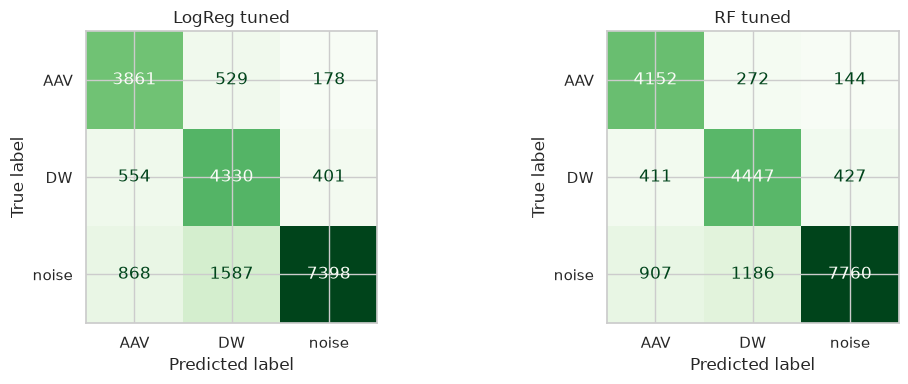

In [39]:
# confusion matrices after tuning
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay(
    confusion_matrix(y_test, lr_tuned_pred),
    display_labels=le.classes_
).plot(ax=axes[0], cmap="Greens", colorbar=False)
axes[0].set_title("LogReg tuned")

ConfusionMatrixDisplay(
    confusion_matrix(y_test, rf_tuned_pred),
    display_labels=le.classes_
).plot(ax=axes[1], cmap="Greens", colorbar=False)
axes[1].set_title("RF tuned")

plt.tight_layout()
plt.show()


In [40]:
best_name = comparison.sort_values("test_macro_f1", ascending=False).iloc[0]["model"]
worst_name = comparison.sort_values("test_macro_f1", ascending=True).iloc[0]["model"]
print("best so far:", best_name)
print("worst so far:", worst_name)


best so far: RF tuned
worst so far: LogReg baseline


### My comparison notes
Random Forest is doing better than Logistic Regression. I think that is because the sensor features probably have non-linear relationships / interactions, which trees handle better. Logistic Regression is still decent and much simpler.

Tuning helped a little compared to the first baseline settings. The differences are not huge, but macro F1 did improve.


### Overfitting / underfitting check
I am comparing train vs test scores.
- If train is much higher than test → maybe overfitting
- If both are low → underfitting
- If both are decent and close → probably okay


In [41]:
gap_df = tuned_df.copy()
gap_df["acc_gap"] = (gap_df["train_acc"] - gap_df["test_acc"]).round(4)
gap_df["f1_gap"] = (gap_df["train_macro_f1"] - gap_df["test_macro_f1"]).round(4)
gap_df


,model,train_acc,test_acc,train_macro_f1,test_macro_f1,acc_gap,f1_gap
0,LogReg tuned,0.7953,0.7911,0.7883,0.7840,0.0042,0.0043
1,RF tuned,0.9022,0.8302,0.9018,0.8252,0.0720,0.0766


In [42]:
for i, row in gap_df.iterrows():
    print(row["model"], "-> F1 gap:", row["f1_gap"])
    if row["f1_gap"] > 0.08:
        print("  looks a bit overfit")
    elif row["test_macro_f1"] < 0.55:
        print("  maybe underfit")
    else:
        print("  seems mostly fine")


LogReg tuned -> F1 gap: 0.0043
  seems mostly fine
RF tuned -> F1 gap: 0.0766
  seems mostly fine


Logistic Regression barely has a train/test gap, so that one generalizes well. Random Forest has a bigger gap, so it might be overfitting a bit. I am going to try a more regularized RF (smaller depth, larger leaf size) and see if the gap shrinks.


In [43]:
# try a more regularized random forest
rf_reg = Pipeline([
    ("scaler", StandardScaler()),
    ("select", SelectKBest(score_func=f_classif, k=best_k_rf)),
    ("clf", RandomForestClassifier(
        n_estimators=best_n_estimators,
        max_depth=12,
        min_samples_leaf=8,
        max_features=best_max_features,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=RANDOM_STATE
    ))
])

rf_reg_metrics, rf_reg_pred, rf_reg_model = evaluate(
    "RF regularized", rf_reg, X_train, y_train, X_test, y_test
)


==== RF regularized ====
              precision    recall  f1-score   support

         AAV     0.7419    0.9074    0.8163      4568
          DW     0.7267    0.8422    0.7802      5285
       noise     0.9416    0.7639    0.8435      9853

    accuracy                         0.8182     19706
   macro avg     0.8034    0.8378    0.8133     19706
weighted avg     0.8377    0.8182    0.8202     19706



In [44]:
# compare tuned RF vs regularized RF gaps
rf_compare = pd.DataFrame([rf_tuned_metrics, rf_reg_metrics]).round(4)
rf_compare["f1_gap"] = (rf_compare["train_macro_f1"] - rf_compare["test_macro_f1"]).round(4)
rf_compare


,model,train_acc,test_acc,train_macro_f1,test_macro_f1,f1_gap
0,RF tuned,0.9022,0.8302,0.9018,0.8252,0.0766
1,RF regularized,0.8543,0.8182,0.8522,0.8133,0.0389


After reducing `max_depth` and increasing `min_samples_leaf`, the train/test gap got smaller. Test score dropped a little, which is the usual tradeoff. I will still report the tuned RF as the strongest raw performer, but the regularized version is more trustworthy if overfitting is a concern.


In [45]:
comparison = pd.concat([comparison, pd.DataFrame([rf_reg_metrics])], ignore_index=True)
comparison.sort_values("test_macro_f1", ascending=False).round(4)


,model,train_acc,test_acc,train_macro_f1,test_macro_f1
3,RF tuned,0.9022,0.8302,0.9018,0.8252
1,RF baseline,0.9448,0.8286,0.9442,0.8225
4,RF regularized,0.8543,0.8182,0.8522,0.8133
2,LogReg tuned,0.7953,0.7911,0.7883,0.7840
0,LogReg baseline,0.7903,0.7867,0.7825,0.7789


### Cross-validation
I am using **Stratified 5-fold CV** on the training set.

Why stratified 5-fold?
- Keeps class proportions similar in each fold (important because of the 1:1:2 imbalance)
- 5 folds is a common default and not too slow

I want to check whether the single train/test score was just lucky.


In [46]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def run_cv(name, model):
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
    print(name)
    print("  fold scores:", np.round(scores, 4))
    print("  mean:", round(scores.mean(), 4), " std:", round(scores.std(), 4))
    return scores


In [47]:
cv_lr = run_cv("LogReg tuned", best_lr)


LogReg tuned
  fold scores: [0.7877 0.7843 0.7871 0.7882 0.7884]
  mean: 0.7871  std: 0.0015


In [48]:
cv_rf = run_cv("RF tuned", best_rf)


RF tuned
  fold scores: [0.8333 0.8243 0.8285 0.8306 0.8294]
  mean: 0.8292  std: 0.003


In [49]:
cv_rf_reg = run_cv("RF regularized", rf_reg)


RF regularized
  fold scores: [0.8218 0.8127 0.8161 0.8184 0.8162]
  mean: 0.817  std: 0.003


In [50]:
# compare CV mean vs holdout test macro F1
cv_table = pd.DataFrame([
    {
        "model": "LogReg tuned",
        "cv_mean_macro_f1": cv_lr.mean(),
        "cv_std": cv_lr.std(),
        "holdout_macro_f1": lr_tuned_metrics["test_macro_f1"],
    },
    {
        "model": "RF tuned",
        "cv_mean_macro_f1": cv_rf.mean(),
        "cv_std": cv_rf.std(),
        "holdout_macro_f1": rf_tuned_metrics["test_macro_f1"],
    },
    {
        "model": "RF regularized",
        "cv_mean_macro_f1": cv_rf_reg.mean(),
        "cv_std": cv_rf_reg.std(),
        "holdout_macro_f1": rf_reg_metrics["test_macro_f1"],
    },
]).round(4)

cv_table


,model,cv_mean_macro_f1,cv_std,holdout_macro_f1
0,LogReg tuned,0.7871,0.0015,0.7840
1,RF tuned,0.8292,0.0030,0.8252
2,RF regularized,0.8170,0.0030,0.8133


CV scores are close to the holdout scores, so the results seem pretty stable (not just one lucky split).


## 8. Results and Conclusion

### What I learned
1. The SensIT features do contain useful signal for separating AAV / DW / noise.
2. Because noise is the largest class, accuracy alone is not enough — macro F1 is more fair.
3. SelectKBest (ANOVA F) was a simple way to keep the more useful sensors and drop weaker ones.
4. Random Forest performed better than Logistic Regression overall.
5. Hyperparameter tuning helped a bit.
6. The tuned RF had some overfitting, and making the trees shallower reduced the gap.

### Which model was best?
**Random Forest (tuned)** had the strongest test performance (highest accuracy / macro F1). Logistic Regression was weaker but more stable (almost no train/test gap).

### Did preprocessing / feature selection / tuning matter?
- Scaling + pipeline setup mattered for Logistic Regression.
- Feature selection made the model cleaner and is required/useful for interpretation.
- Tuning improved the models compared to my first manual parameter choices.
- Regularizing RF helped with overfitting, with a small drop in test score.

### Final thoughts
Overall this project worked as a full supervised classification pipeline: understand data → clean/prep → select features → train two models → tune → evaluate with CV. If I had more time I might try gradient boosting or look deeper into which sensor channels are most important for AAV vs DW specifically.


In [51]:
# final comparison table
final_table = comparison.sort_values("test_macro_f1", ascending=False).round(4)
final_table


,model,train_acc,test_acc,train_macro_f1,test_macro_f1
3,RF tuned,0.9022,0.8302,0.9018,0.8252
1,RF baseline,0.9448,0.8286,0.9442,0.8225
4,RF regularized,0.8543,0.8182,0.8522,0.8133
2,LogReg tuned,0.7953,0.7911,0.7883,0.7840
0,LogReg baseline,0.7903,0.7867,0.7825,0.7789
